# Quick start

In [12]:
import numpy as np
import pandas as pd
import matplotlib as mpl
from anndata import AnnData
import matplotlib.pyplot as plt
import spatialdata as sd
from spatialdata.models import TableModel
import spatialdata_plot
from matplotlib.patches import Patch
from typing import Literal

assert spatialdata_plot.__version__ == "0.2.13"

_AX_BG_COLOR = "black"

In [13]:
## Load provided SpatialData object
sdata = sd.read_zarr("../data/ST8059048.zarr")
sdata

SpatialData object, with associated Zarr store: /Users/berni/PycharmProjects/rectangle_paper/data/ST8059048.zarr
├── Shapes
│     └── 'ST8059048': GeoDataFrame shape: (2987, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (2987, 31053)
with coordinate systems:
    ▸ 'ST8059048', with elements:
        ST8059048 (Shapes)
    ▸ 'ST8059048_downscaled_hires', with elements:
        ST8059048 (Shapes)
    ▸ 'ST8059048_downscaled_lowres', with elements:
        ST8059048 (Shapes)

In [14]:
estimations = pd.read_csv("../data/spatial_estimations_ST8059048.csv", index_col=0)
estimations

,Astro_AMY,Astro_HPC,Astro_HYPO,Astro_THAL,Astro_WM,Ext_Amy,Ext_ClauPyr,Ext_Hpc,Ext_L23,Ext_L25,...,Inh_Lamp5,Inh_Meis2,Inh_Pvalb,Inh_Sst,Inh_Vip,Micro,Nb,OPC,Oligo,Unknown
AAACAAGTATCTCCCA-1,7.310477e-19,2.300445e-01,0.033473,3.665944e-18,0.104291,0.000000e+00,0.000000e+00,1.203682e-18,0.000000,0.000000e+00,...,7.392568e-03,0.000000e+00,1.341368e-18,0.000000e+00,0.000000e+00,0.044220,0.000000e+00,0.000000e+00,0.153600,0.257754
AAACACCAATAACTGC-1,0.000000e+00,2.702850e-01,0.001302,0.000000e+00,0.472688,6.370821e-05,1.299241e-20,2.708118e-02,0.011612,0.000000e+00,...,3.246042e-03,1.202721e-03,0.000000e+00,0.000000e+00,8.241025e-03,0.021025,0.000000e+00,1.252867e-19,0.161303,0.000000
AAACAGAGCGACTCCT-1,0.000000e+00,4.395926e-02,0.000683,0.000000e+00,0.227120,3.680784e-18,1.865512e-04,0.000000e+00,0.181651,2.403470e-04,...,5.464837e-03,1.557281e-18,1.420217e-19,4.803913e-05,5.674234e-20,0.051633,5.071651e-03,0.000000e+00,0.102967,0.318703
AAACAGCTTTCAGAAG-1,3.594137e-18,2.262370e-01,0.001132,0.000000e+00,0.296858,1.024798e-18,2.466663e-03,2.921593e-19,0.152393,2.010963e-02,...,6.323059e-03,3.391769e-18,1.434886e-04,1.061747e-19,3.396582e-04,0.078027,7.941228e-03,8.696917e-19,0.026568,0.125464
AAACAGGGTCTATATT-1,4.438465e-18,0.000000e+00,0.001795,1.948421e-19,0.470842,0.000000e+00,1.194575e-03,3.441819e-18,0.272008,0.000000e+00,...,7.536107e-21,6.017816e-19,0.000000e+00,7.225355e-05,2.388022e-19,0.025426,8.756374e-03,1.309959e-02,0.012614,0.192775
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,5.772219e-19,4.848803e-02,0.000131,3.056430e-18,0.047214,2.841791e-17,2.288170e-03,3.987017e-01,0.000000,2.466624e-04,...,1.262053e-19,0.000000e+00,1.988436e-19,0.000000e+00,2.256559e-20,0.007907,0.000000e+00,5.867369e-20,0.043753,0.400768
TTGTTGTGTGTCAAGA-1,0.000000e+00,1.140891e-01,0.000369,1.256428e-01,0.145578,0.000000e+00,7.413854e-20,0.000000e+00,0.025898,2.505370e-05,...,1.498463e-19,0.000000e+00,0.000000e+00,1.364735e-19,0.000000e+00,0.005517,0.000000e+00,0.000000e+00,0.292881,0.225505
TTGTTTCACATCCAGG-1,5.960432e-18,1.033495e-01,0.000453,0.000000e+00,0.175840,5.642409e-02,0.000000e+00,1.338280e-04,0.184871,8.676455e-20,...,2.071514e-02,5.043638e-19,2.149011e-19,8.207536e-02,7.280564e-03,0.048402,1.374068e-03,0.000000e+00,0.037212,0.263848
TTGTTTCATTAGTCTA-1,8.753454e-18,0.000000e+00,0.005156,0.000000e+00,0.303371,2.926869e-03,1.848097e-03,0.000000e+00,0.000000,2.111148e-18,...,2.587341e-02,0.000000e+00,2.822573e-05,7.012637e-02,6.965273e-03,0.019607,3.557355e-04,2.942965e-04,0.066800,0.397253


In [15]:
def _get_most_likely_cell_type(rectangle_results, ):
    """Takes in a DataFrame representing the results of Rectangle deconvolution and returns
    a DataFrame with the most likely cell type for each observation. For each observation, the most likely cell type is selected and the likelihood of
    the others is set to 0. Then, the cell types are sorted by abundance.
    """
    # Select only numeric columns to avoid string comparison errors
    numeric_cols = rectangle_results.select_dtypes(include=[np.number]).columns.tolist()

    if not numeric_cols:
        raise ValueError("No numeric columns found in rectangle_results")

    arr = rectangle_results[numeric_cols].to_numpy(copy=False)
    idx = arr.argmax(axis=1)
    out = np.zeros_like(arr)
    rows = np.arange(arr.shape[0])
    out[rows, idx] = arr[rows, idx]

    out_df = rectangle_results.copy()
    out_df.loc[:, numeric_cols] = out

    # Sort by abundance (count of non-zero values)
    celltype_abundance = (out_df[numeric_cols] > 0).sum(axis=0)
    celltype_abundance = celltype_abundance.sort_values(ascending=False)

    return out_df.loc[:, celltype_abundance.index.values.tolist()]


def add_rectangle_results_to_spatialdata(
    sdata,
    estimations: pd.DataFrame,
    celltypes: list,
    *,
    table_name: str = "rectangle_results",
    region_name: str = "ST8059048",
    source_table: str = "table",
):
    """Process Rectangle deconvolution estimations and add them to a SpatialData object.

    Parameters
    ----------
    sdata
        The SpatialData object to add results to
    estimations
        DataFrame containing Rectangle deconvolution estimations (observations as index,
        cell types as columns)
    celltypes
        List of cell type column names to include in the analysis
    table_name
        Name of the table to store results in sdata.tables. Default: "rectangle_results"
    region_name
        Name of the region for spatialdata attributes. Default: "ST8059048"
    source_table
        Name of the source table in sdata.tables to merge spot_id from. Default: "table"

    Returns
    -------
    None
        Modifies sdata in place by adding the processed table to sdata.tables[table_name]

    """
    # Process the estimations
    cleaned_results = _get_most_likely_cell_type(estimations[celltypes])

    # Create AnnData object
    table_data = AnnData(cleaned_results)
    adata_for_sdata = TableModel.parse(table_data)

    # Clean up the spot_id by filtering out bad indices
    spot_id_df = adata_for_sdata.obs.merge(
        sdata.tables[source_table].obs, left_index=True, right_index=True, how="left"
    )

    # Filter out observations with invalid spot_id
    bad_mask = np.isnan(spot_id_df["spot_id"].values)
    good_idx = spot_id_df[~bad_mask].index.values

    # Filter the AnnData object to only include good indices
    adata_for_sdata = adata_for_sdata[good_idx, :].copy()

    # Set up spatialdata attributes
    adata_for_sdata.uns["spatialdata_attrs"] = {
        "region": region_name,
        "region_key": "region",
        "instance_key": "spot_id",
    }

    # Add region and spot_id to observations
    adata_for_sdata.obs["region"] = pd.Categorical([region_name] * len(adata_for_sdata))
    adata_for_sdata.obs["spot_id"] = spot_id_df.loc[good_idx, "spot_id"].values.astype(int)

    # Add to spatialdata object
    sdata.tables[table_name] = adata_for_sdata

    # Sanitize, not sure why there are NaNs
    sdata.tables[table_name].X = sdata.tables[table_name].to_df().fillna(0).values

celltypes_to_viz = [
    "Ext_L23",
    "Ext_L25",
    "Ext_L5",
    "Ext_L56",
    "Ext_L6B"
]

add_rectangle_results_to_spatialdata(
    sdata=sdata,
    estimations=estimations,
    celltypes=celltypes_to_viz,
    table_name="rectangle_results",
    region_name="ST8059048",
    source_table="table"
)

sdata.tables["rectangle_results"].to_df()

,Ext_L23,Ext_L56,Ext_L25,Ext_L6B,Ext_L5
AAACAAGTATCTCCCA-1,0.000000,0.000112,0.0,0.0,0.0
AAACACCAATAACTGC-1,0.011612,0.000000,0.0,0.0,0.0
AAACAGAGCGACTCCT-1,0.181651,0.000000,0.0,0.0,0.0
AAACAGCTTTCAGAAG-1,0.152393,0.000000,0.0,0.0,0.0
AAACAGGGTCTATATT-1,0.272008,0.000000,0.0,0.0,0.0
...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1,0.000000,0.032949,0.0,0.0,0.0
TTGTTGTGTGTCAAGA-1,0.025898,0.000000,0.0,0.0,0.0
TTGTTTCACATCCAGG-1,0.184871,0.000000,0.0,0.0,0.0
TTGTTTCATTAGTCTA-1,0.000000,0.005879,0.0,0.0,0.0


In [16]:


celltypes = [
    "Ext_L23",
    "Ext_L25",
    "Ext_L5",
    "Ext_L56",
    "Ext_L6B"
]
colors = [
    "Purple",
    "Blue",
    "Green",
    "Yellow",
    "Orange"
]

celltype_color_map = dict(zip(celltypes, colors))
celltype_color_map

{'Ext_L23': 'Purple',
 'Ext_L25': 'Blue',
 'Ext_L5': 'Green',
 'Ext_L56': 'Yellow',
 'Ext_L6B': 'Orange'}

INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


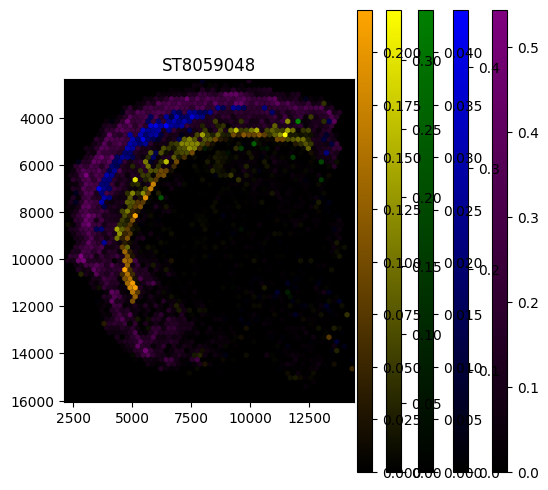

In [18]:
def transparent_sequential_cmap(
    color: str, n: int = 256, bg: Literal["white", "black"] = "black", name: str | None = None
) -> mpl.colors.ListedColormap:
    """Create a cmap from `color` to `bg` where value 0 is fully transparent."""
    rgb_target = np.array(mpl.colors.to_rgb(color), dtype=float)
    if bg == "white":
        bg_color = np.ones(3, dtype=float)
    elif bg == "black":
        bg_color = np.zeros(3, dtype=float)
    else:
        raise ValueError(f"bg must be 'white' or 'black', got {bg!r}")

    t = np.linspace(0.0, 1.0, n)  # 0 → 1 along the colormap
    rgb = (1.0 - t)[:, None] * bg_color[None, :] + t[:, None] * rgb_target[None, :]  # white → color
    alpha = t  # 0 at start, 1 at end

    rgba = np.concatenate([rgb, alpha[:, None]], axis=1)
    return mpl.colors.ListedColormap(rgba, name or f"{color}_transparent_seq")

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_facecolor("black")       # axis background

for celltype, color in celltype_color_map.items():
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg='black')
    (
        sdata
        .pl.render_shapes(
            color=celltype,
            cmap=cmap,
            shape="visium_hex",
            table_name="rectangle_results",
        )
        .pl.show(
            "ST8059048",
            ax=ax,
            colorbar=True
        )
    )

# handles = [
#     Patch(facecolor=c, edgecolor="none", label=lab)
#     for lab, c in zip(celltypes, colors)
# ]
# ax.legend(
#     handles=handles,
#     title="Cell type",
#     loc="center left",
#     bbox_to_anchor=(1.02, 0.5),  # outside to the right
#     borderaxespad=0.0,
#     frameon=False,
#     ncol=1,
# )

INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


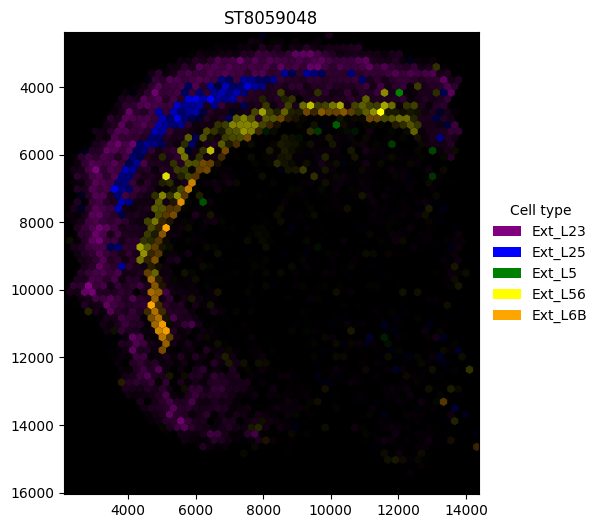

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_facecolor(_AX_BG_COLOR)       # axis background


for celltype, color in celltype_color_map.items():
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg=_AX_BG_COLOR)
    (
        sdata
        .pl.render_shapes(
            color=celltype,
            cmap=cmap,
            shape="visium_hex",
            table_name="rectangle_results",
        )
        .pl.show(
            "ST8059048",
            ax=ax,
            colorbar=False
        )
    )

handles = [
    Patch(facecolor=c, edgecolor="none", label=lab)
    for lab, c in zip(celltypes, colors)
]
ax.legend(
    handles=handles,
    title="Cell type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  # outside to the right
    borderaxespad=0.0,
    frameon=False,
    ncol=1,
)

INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


INFO     Converting 2963 shapes to visium_hex.                                                                     


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `ST8059048` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `rectangle_results` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


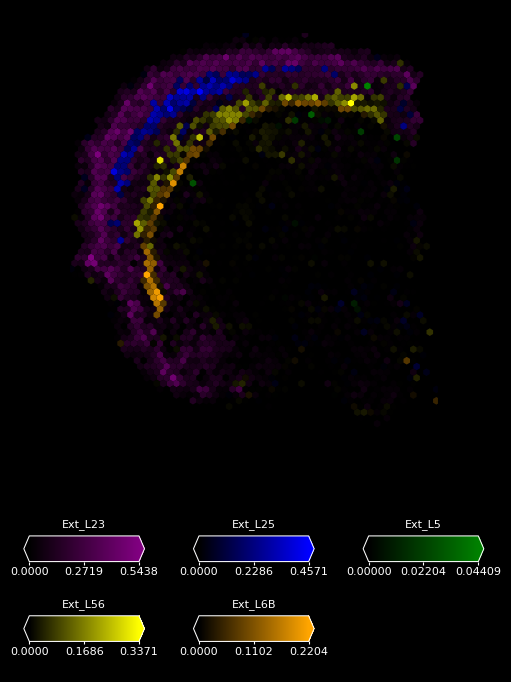

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colorbar import ColorbarBase
from matplotlib.colors import Normalize, Colormap


def add_celltype_colorbar(
    ax: plt.Axes,
    values: np.ndarray,
    cmap: Colormap,
    name: str,
    *,
    bg: str = "black",
    text_color: str = "white",
    n_ticks: int = 3,
    bar_y: float = 0.12,
    bar_h: float = 0.45,
    outline_color: str = "white",
    outline_width: float = 0.75,
) -> None:
    vals = np.asarray(values, float)
    vals = vals[~np.isnan(vals)]
    if vals.size == 0:
        vmin, vmax = 0.0, 1.0
    else:
        vmin, vmax = float(vals.min()), float(vals.max())
        if vmin == vmax:
            vmin -= 0.5
            vmax += 0.5

    # make an opaque version of the cmap (no fade-to-white effect)
    base = cmap(np.linspace(0.0, 1.0, 256))
    base[:, 3] = 1.0  # alpha = 1
    cmap_opaque = mpl.colors.ListedColormap(base, name=f"{cmap.name}_opaque")

    # outer slot
    ax.set_facecolor(bg)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)

    # inner bar
    bar_ax = ax.inset_axes([0.02, bar_y, 0.96, bar_h])
    bar_ax.set_facecolor(bg)

    cbar = ColorbarBase(
        bar_ax,
        cmap=cmap_opaque,
        norm=Normalize(vmin=vmin, vmax=vmax),
        orientation="horizontal",
        extend="both",
        extendfrac=0.05,
    )

    # ticks
    ticks = np.linspace(vmin, vmax, n_ticks)
    cbar.set_ticks(ticks)
    cbar.ax.tick_params(colors=text_color, labelsize=8, length=2, pad=2)

    # white outline
    for spine in bar_ax.spines.values():
        spine.set_edgecolor(outline_color)
        spine.set_linewidth(outline_width)

    # title
    title_to_cmap_pad = 0.10
    ax.text(
        0.5,
        bar_y + bar_h + title_to_cmap_pad,
        name,
        ha="center",
        va="bottom",
        color=text_color,
        fontsize=8,
        transform=ax.transAxes,
    )

# 1) Set up the figure and layout
fig = plt.figure(figsize=(6, 8), facecolor="black")

# top: 3/4, bottom: 1/4
gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[3, 1],
    hspace=0.25,
)
# bottom area: 2 rows × 3 cols
bottom_gs = gs[1].subgridspec(
    nrows=2,
    ncols=3,
    wspace=0.35,
    hspace=0.4,
)
bottom_axs = bottom_gs.subplots()
bottom_axs = bottom_axs.flatten()

# 2) Define celltypes and colors and prepare the SpatialData object
celltypes_to_viz = [
    "Ext_L23",
    "Ext_L25",
    "Ext_L5",
    "Ext_L56",
    "Ext_L6B"
]

colors = [
    "Purple",
    "Blue",
    "Green",
    "Yellow",
    "Orange"
]
celltype_color_map = dict(zip(celltypes_to_viz, colors))

add_rectangle_results_to_spatialdata(
    sdata=sdata,
    estimations=estimations,
    celltypes=celltypes_to_viz,
    table_name="rectangle_results",
    region_name="ST8059048",
    source_table="table",
)

# 3) Draw the hex plot
top_ax = fig.add_subplot(gs[0])
for celltype, color in celltype_color_map.items():
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg=_AX_BG_COLOR)
    (
        sdata.pl.render_shapes(
            color=celltype,
            cmap=cmap,
            shape="visium_hex",
            table_name="rectangle_results",
        ).pl.show("ST8059048", ax=top_ax, colorbar=False)
    )

top_ax.set_facecolor("black")

# 4) Draw the colorbars
for i, (celltype, color) in enumerate(celltype_color_map.items()):
    cmap = transparent_sequential_cmap(color, n=256, name=f"{celltype}_transparent_seq", bg=_AX_BG_COLOR)
    add_celltype_colorbar(
        bottom_axs[i],
        sdata.tables["rectangle_results"].to_df()[celltype],
        cmap,
        celltype,
    )

# Ensure that unused colorbars are black.
for ax in bottom_axs:
    ax.set_facecolor("black")

plt.show()
